In [ ]:
# Connect Google Drive to Colab
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Note: file paths point to Google Drive. Data files are in the /data folder of this repo.

In [ ]:
# Load the datasets
import pandas as pd

path = '/content/drive/MyDrive/Portofolio/Data-Analyst/shopeasy-project/'
orders = pd.read_csv(path + 'orders.csv')
customers = pd.read_csv(path + 'customers.csv')
products = pd.read_csv(path + 'products.csv')

print(orders.shape)
orders.head()

(3187, 8)


,order_id,order_date,customer_id,product_id,quantity,discount_pct,payment_method,status
0,ORD00001,2024-11-23,C0090,P019,1,20,Bank Transfer,Completed
1,ORD00002,2024-09-09,C0024,P010,1,0,Bank Transfer,Completed
2,ORD00003,2024-05-02,C0203,P017,2,10,Credit Card,Completed
3,ORD00004,2024-12-07,C0157,P006,3,5,COD,Completed
4,ORD00005,2024-02-19,C0492,P025,5,0,COD,Completed


In [ ]:
# Check for problems before fixing anything
print(orders.isna().sum())          # missing values per column
print(orders.duplicated().sum())    # number of duplicate rows
print(orders['quantity'].describe())  # look for outliers
print(orders['payment_method'].unique())  # inconsistent text
print(customers['city'].isna().sum())     # missing cities

order_id           0
order_date         0
customer_id        0
product_id         0
quantity           0
discount_pct       0
payment_method     0
status            30
dtype: int64
39
count    3187.000000
mean        1.939128
std         3.993882
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        99.000000
Name: quantity, dtype: float64
['Bank Transfer' 'Credit Card' 'COD' 'e-wallet' 'E-Wallet' 'cod'
 'credit card' 'bank transfer']
25


In [ ]:
# 1. Remove duplicate rows
orders = orders.drop_duplicates()

# 2. Standardize payment method text
orders['payment_method'] = (
    orders['payment_method']
    .str.lower()
    .replace({'bank transfer': 'Bank Transfer', 'e-wallet': 'E-Wallet',
              'cod': 'COD', 'credit card': 'Credit Card'})
)

# 3. Fill missing values
orders['status'] = orders['status'].fillna('Unknown')
customers['city'] = customers['city'].str.title().fillna('Unknown')

# 4. Remove unrealistic quantities
orders = orders[orders['quantity'] <= 10]

# Verify
print(orders.shape)
print(orders.isna().sum().sum())
print(orders['payment_method'].unique())

(3143, 8)
0
['Bank Transfer' 'Credit Card' 'COD' 'E-Wallet']


In [ ]:
orders.to_csv(path + 'orders_clean.csv', index=False)
customers.to_csv(path + 'customers_clean.csv', index=False)

In [ ]:
import sqlite3

conn = sqlite3.connect(':memory:')  # temporary database in RAM
orders.to_sql('orders', conn, index=False, if_exists='replace')
customers.to_sql('customers', conn, index=False, if_exists='replace')
products.to_sql('products', conn, index=False, if_exists='replace')

40

In [ ]:
query = """
SELECT strftime('%Y-%m', o.order_date) AS month,
       ROUND(SUM(p.price * o.quantity * (1 - o.discount_pct / 100.0))) AS revenue
FROM orders o
JOIN products p ON o.product_id = p.product_id
WHERE o.status = 'Completed'
GROUP BY month
ORDER BY month;
"""

# 1. Create the table first
monthly = pd.read_sql(query, conn)

# 2. Then sort it to find the top months
monthly.sort_values('revenue', ascending=False).head(5)

,month,revenue
11,2024-12,262625550.0
10,2024-11,252171100.0
22,2025-11,236846550.0
23,2025-12,227639500.0
7,2024-08,186183900.0


In [ ]:
query = """
SELECT p.product_name, p.category,
       ROUND(SUM(p.price * o.quantity * (1 - o.discount_pct / 100.0))) AS revenue
FROM orders o
JOIN products p ON o.product_id = p.product_id
WHERE o.status = 'Completed'
GROUP BY p.product_name, p.category
ORDER BY revenue DESC
LIMIT 5;
"""
top_products = pd.read_sql(query, conn)
top_products

,product_name,category,revenue
0,Backpack,Fashion,156472400.0
1,Badminton Racket,Sports,156469200.0
2,Electric Kettle,Home & Living,146856000.0
3,Gym Gloves,Sports,146778800.0
4,Smartwatch,Electronics,144640500.0


In [ ]:
query = """
SELECT c.city,
       ROUND(SUM(p.price * o.quantity * (1 - o.discount_pct / 100.0))) AS revenue
FROM orders o
JOIN products p ON o.product_id = p.product_id
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.status = 'Completed'
GROUP BY c.city
ORDER BY revenue DESC;
"""
city_revenue = pd.read_sql(query, conn)
city_revenue

,city,revenue
0,Jakarta,930777600.0
1,Bandung,456745800.0
2,Surabaya,451038250.0
3,Semarang,345152350.0
4,Medan,277545900.0
5,Palembang,260819700.0
6,Pekanbaru,256809900.0
7,Makassar,228761100.0
8,Unknown,212508300.0
9,Yogyakarta,201201950.0


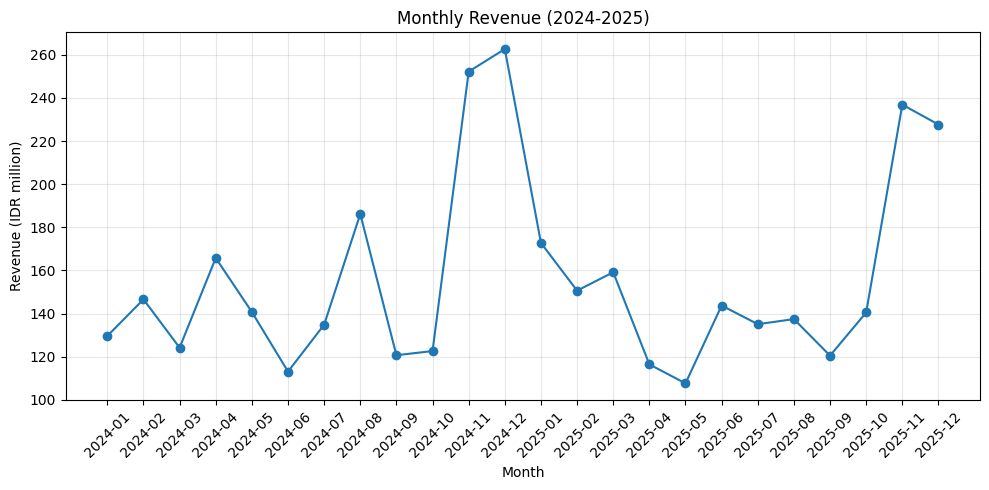

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(monthly['month'], monthly['revenue'] / 1_000_000, marker='o')
plt.title('Monthly Revenue (2024-2025)')
plt.xlabel('Month')
plt.ylabel('Revenue (IDR million)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(path + 'monthly_revenue.png', dpi=150)
plt.show()

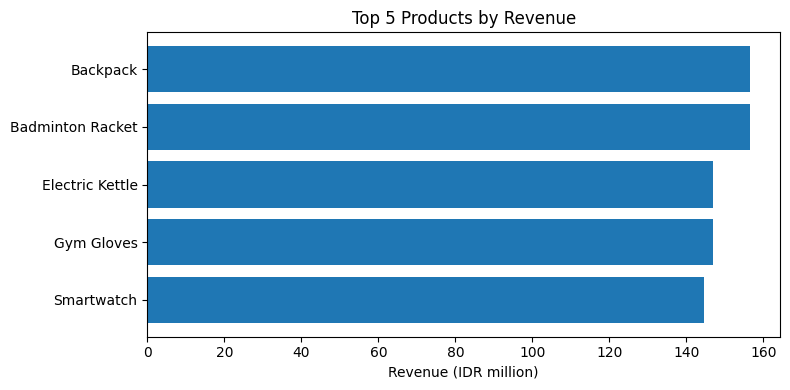

In [ ]:
plt.figure(figsize=(8, 4))
plt.barh(top_products['product_name'], top_products['revenue'] / 1_000_000)
plt.title('Top 5 Products by Revenue')
plt.xlabel('Revenue (IDR million)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(path + 'top_products.png', dpi=150)
plt.show()

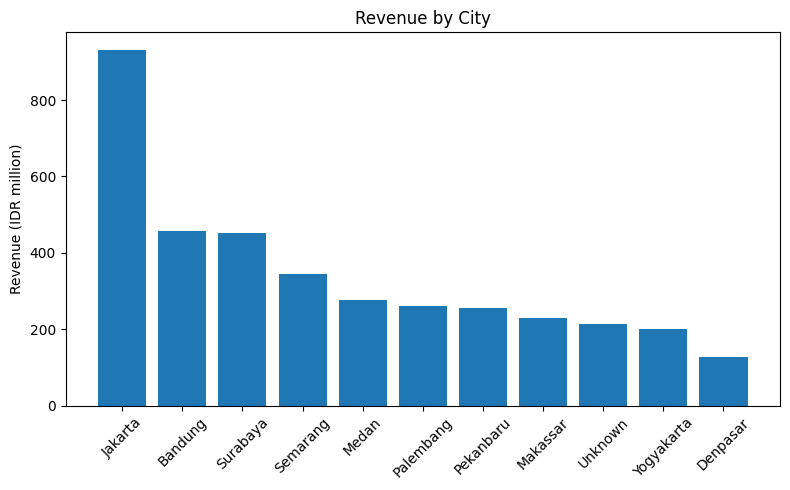

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(city_revenue['city'], city_revenue['revenue'] / 1_000_000)
plt.title('Revenue by City')
plt.ylabel('Revenue (IDR million)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(path + 'city_revenue.png', dpi=150)
plt.show()

In [ ]:
# Combine 3 tables into 1 flat table for the dashboard
df = orders.merge(products, on='product_id').merge(customers, on='customer_id')

# Calculate revenue per row
df['revenue'] = df['price'] * df['quantity'] * (1 - df['discount_pct'] / 100)

# Keep completed orders only (same as our SQL queries)
df = df[df['status'] == 'Completed']

df.to_csv(path + 'dashboard_data.csv', index=False)
print(df.shape)
df.head()

(2779, 16)


,order_id,order_date,customer_id,product_id,quantity,discount_pct,payment_method,status,product_name,category,price,city,gender,age,signup_date,revenue
0,ORD00001,2024-11-23,C0090,P019,1,20,Bank Transfer,Completed,LED Lamp,Home & Living,1264000,Palembang,Male,41,2024-02-19,1011200.0
1,ORD00002,2024-09-09,C0024,P010,1,0,Bank Transfer,Completed,Dress Shirt,Fashion,168000,Surabaya,Female,20,2024-08-18,168000.0
2,ORD00003,2024-05-02,C0203,P017,2,10,Credit Card,Completed,Rice Cooker,Home & Living,784000,Pekanbaru,Male,29,2023-05-07,1411200.0
3,ORD00004,2024-12-07,C0157,P006,3,5,COD,Completed,Mini Speaker,Electronics,1292000,Bandung,Female,26,2024-12-02,3682200.0
4,ORD00005,2024-02-19,C0492,P025,5,0,COD,Completed,Face Serum,Beauty,1178000,Yogyakarta,Female,27,2024-04-05,5890000.0
